# Universidad de Buenos Aires
# Aprendizaje Profundo - TP3
# Cohorte 26 - 4to bimestre 2026


## **Alumno 1:** Denis Zhbankov  
## **Alumno 2:** Elián Pinzás  
## **Alumno 3:** Gonzalo Rodriguez

# **CLASIFICADOR DE EMOCIONES**

El objetivo de este trabajo es construir una red neuronal convolucional (CNN) utilizando Pytorch, capaz de clasificar emociones humanas a partir de imágenes faciales. El clasificador deberá identificar una de las 7 emociones básicas: alegría, tristeza, enojo, miedo, sorpresa, disgusto y seriedad.

El dataset se encuentra en este link: https://drive.google.com/file/d/1aPHE00zkDhEV1waJKhaOJMdN6-lUc0iT/view?usp=sharing

In [1]:
import torch
import torchvision
import numpy as np
import random
import matplotlib.pyplot as plt
from matplotlib import image
from matplotlib import pyplot
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts
from tqdm import tqdm


In [2]:
import gdown
import zipfile
import os

url = "https://drive.google.com/uc?id=1aPHE00zkDhEV1waJKhaOJMdN6-lUc0iT"
output = "archivo.zip"

gdown.download(url, output, quiet=False)

destino = "datos_zip"
os.makedirs(destino, exist_ok=True)

with zipfile.ZipFile(output, 'r') as zip_ref:
    zip_ref.extractall(destino)

import sys
en_colab = 'google.colab' in sys.modules
base_path = '/content/datos_zip/dataset_emociones' if en_colab else 'datos_zip/dataset_emociones'

DATASET_ROOT_TRAIN = f'{base_path}/train'
DATASET_ROOT_VAL   = f'{base_path}/validation'


Downloading...
From (original): https://drive.google.com/uc?id=1aPHE00zkDhEV1waJKhaOJMdN6-lUc0iT
From (redirected): https://drive.google.com/uc?id=1aPHE00zkDhEV1waJKhaOJMdN6-lUc0iT&confirm=t&uuid=9fdea056-fcf9-4a89-bca9-81773af13ffd
To: /content/archivo.zip
100%|██████████| 40.0M/40.0M [00:00<00:00, 55.8MB/s]


## 1. Preprocesamiento de Datos (2 puntos)

Antes de entrenar el modelo, se debe analizar qué tipo de preprocesamiento se debe aplicar a las imágenes. Para esto, se puede considerar uno o más aspectos como:

- Tamaño
- Relación de aspecto
- Color o escala de grises
- Cambio de dimensionalidad
- Normalización
- Balanceo de datos
- Data augmentation
- etc.

Sean criteriosos y elijan solo las técnicas que consideren pertinentes para este caso de uso en específico.

Recomendación: usar `torchvision.transforms` para facilitar el preprocesamiento. Lean su documentación si tienen dudas: https://docs.pytorch.org/vision/0.14/transforms.html



### • Tamaño

Se recorre **todo** el dataset (train y validation, las 7 clases) para verificar si las imagenes vienen todas con el mismo tamano o no.

In [3]:
import os
from PIL import Image
from collections import Counter

def analizar_dataset(root_dir):
    tamanios = Counter()
    modos = Counter()
    conteo_por_clase = {}
    for clase in sorted(os.listdir(root_dir)):
        clase_path = os.path.join(root_dir, clase)
        if not os.path.isdir(clase_path):
            continue
        archivos = [f for f in os.listdir(clase_path) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
        conteo_por_clase[clase] = len(archivos)
        for f in archivos:
            with Image.open(os.path.join(clase_path, f)) as img:
                tamanios[img.size] += 1
                modos[img.mode] += 1
    return tamanios, modos, conteo_por_clase

tamanios_train, modos_train, conteo_train = analizar_dataset(DATASET_ROOT_TRAIN)
tamanios_val, modos_val, conteo_val = analizar_dataset(DATASET_ROOT_VAL)

print("=== TRAIN ===")
print("Tamanios distintos encontrados:", len(tamanios_train))
for tam, n in tamanios_train.most_common():
    print(f"  {tam}: {n} imagenes")
print("Modos de color:", dict(modos_train))

print("\n=== VALIDATION ===")
print("Tamanios distintos encontrados:", len(tamanios_val))
for tam, n in tamanios_val.most_common():
    print(f"  {tam}: {n} imagenes")
print("Modos de color:", dict(modos_val))

=== TRAIN ===
Tamanios distintos encontrados: 1
  (100, 100): 12271 imagenes
Modos de color: {'RGB': 12271}

=== VALIDATION ===
Tamanios distintos encontrados: 1
  (100, 100): 3068 imagenes
Modos de color: {'RGB': 3068}


**Conclusion:** todas las imagenes, tanto en train como en validation, tienen tamano **100x100 pIxELES** y modo de color **RGB**, sin excepciones. Aun asi, se agrega un `Resize((100, 100))` en el pipeline de transformaciones como medida de seguridad por si intentan ingresar una imagen con otro tamaño y que el pipeline la lleve igualmente a la dimension esperada por la red.

### • Relación de aspecto

Como todas las imagenes son de 100x100 px, la relacion de aspecto es **1:1** (imagenes cuadradas) en el 100% de los casos. Al no haber imagenes rectangulares, aplicar `Resize` a un tamano cuadrado no introduce ninguna distorsion (estiramiento/aplastamiento) sobre los rasgos faciales. La definicion del tamano final de entrada a la red (mantener 100x100 o reducirlo, por ejemplo a 48x48) se deja pendiente para el punto 2, en conjunto con la decision de arquitectura (tamano de kernel, cantidad de capas de pooling).

### • Color o escala de grises

Se decide convertir las imagenes a **escala de grises** (`Grayscale`).

Argumentos:

- Las expresiones faciales se especifican principalmente en geometria y textura (forma de ojos, cejas, boca, arrugas, dientes visibles), no en el color.
- Reduce el costo computacional a un tercio, al pasar de 3 canales (RGB) a 1.
- Evita que la red aprenda correlaciones entre tono de piel/iluminacion y la clase a predecir, lo que ayuda a generalizar mejor entre personas distintas.
- La informacion de color que se pierde (por ejemplo, rubor o palidez asociados a algunas emociones) es una senal debil y poco confiable comparada con la geometria facial.

### • Cambio de dimensionalidad

Al cargar las imagenes con `ImageFolder`, estas se abren internamente con PIL, quedando representadas con los ejes (Alto, Ancho, Canales). La capa `Conv2d` de PyTorch espera los canales primero: (Canales, Alto, Ancho). La transformacion `ToTensor()` se encarga de este cambio de forma, convirtiendo la imagen PIL en un tensor de PyTorch con los ejes reordenados y, al ser escala de grises, la forma final queda (1, Alto, Ancho) - un solo canal, en la forma que requiere `Conv2d` para procesarla.

### • Normalización

Los valores de pixel originales van de 0 a 255. `ToTensor()` ya los escala a flotantes entre 0 y 1, pero esa distribucion sigue sin estar centrada. Por eso se aplica ademas una estandarizacion (`Normalize`), que resta la media y divide por el desvio estandar, dejando los valores centrados en 0 con desvio 1 - esto favorece la convergencia del descenso de gradiente y evita sesgar las activaciones de las primeras capas.

La media y el desvio se calculan **sobre las imagenes de train** (nunca incluyendo validacion, para no filtrar informacion de ese set), en lugar de usar valores teoricos de otro dataset, para que la normalizacion refleje la distribucion real de estas imagenes en escala de grises.

In [4]:
from torchvision import transforms, datasets
from torch.utils.data import DataLoader

# Transform parcial, sin Normalize, que es lo que se va a calcular
transform_para_stats = transforms.Compose([
    transforms.Grayscale(),
    transforms.ToTensor()
])

dataset_train_stats = datasets.ImageFolder(root=DATASET_ROOT_TRAIN, transform=transform_para_stats)
loader_stats = DataLoader(dataset_train_stats, batch_size=256, shuffle=False)

suma = 0.0
suma_cuadrados = 0.0
n_pixeles = 0

for imgs, _ in loader_stats:
    suma += imgs.sum().item()
    suma_cuadrados += (imgs ** 2).sum().item()
    n_pixeles += imgs.numel()

media = suma / n_pixeles
desvio = (suma_cuadrados / n_pixeles - media ** 2) ** 0.5

print(f"Media: {media:.4f}, Desvio estandar: {desvio:.4f}")

Media: 0.4816, Desvio estandar: 0.2427


### • Balanceo de datos y Data augmentation

El dataset presenta un desbalanceo significativo entre clases: en train, la expresión alegria tiene 4772 imagenes mientras que la expresión miedo tiene solo 281 (un deficit de mas del 90% respecto a la clase mayoritaria), con el resto de las clases en valores intermedios.

Se evaluo usar data augmentation para sobremuestrear las clases minoritarias hasta igualarlas con las mayoritarias, pero se descarto como estrategia de balanceo: igualar miedo a la clase mayoritaria requeriria generar del orden de 16 variantes por cada imagen original de esa clase (o ~9 variantes si se usa como referencia la segunda clase con mas datos). Ese nivel de sobremuestreo sobre un conjunto tan chico de imagenes originales implica que el modelo veria repetidamente transformaciones de las mismas pocas caras, con alto riesgo de memorizarlas en vez de aprender a generalizar la expresion en caras distintas. El data augmentation para balanceo es razonable cuando el desbalance es moderado (del orden de un 5-10%), pero no cuando la brecha es tan grande como en este dataset.

Por eso, **el balanceo de clases se resuelve ponderando la funcion de perdida** (`CrossEntropyLoss` con parametro `weight`, inversamente proporcional a la frecuencia de cada clase en train), lo cual corrige el sesgo del entrenamiento hacia la clase mayoritaria sin generar datos sinteticos adicionales ni arriesgar sobreajuste por repeticion.

**El data augmentation, en cambio, se aplica de forma pareja a todas las clases** (no solo a las minoritarias), con el unico objetivo de mejorar la generalizacion del modelo ante variaciones naturales, y no como mecanismo de balanceo. Se usan tres transformaciones moderadas:

- `RandomHorizontalFlip(p=0.5)`: espeja la imagen horizontalmente con 50% de probabilidad: una expresion espejada sigue representando la misma emocion.
- `RandomRotation(degrees=10)`: simula pequenas inclinaciones naturales de la cabeza/camara, sin deformar la expresion.
- `ColorJitter(brightness=0.2, contrast=0.2)`: simula variaciones de iluminacion entre fotos, sin lavar los detalles finos de la cara.

In [5]:
import torch

clases_ordenadas = dataset_train_stats.classes
conteo_por_indice = [conteo_train[c] for c in clases_ordenadas]
total = sum(conteo_por_indice)

pesos_clases = torch.tensor([total / c for c in conteo_por_indice], dtype=torch.float32)
pesos_clases = pesos_clases / pesos_clases.sum() * len(clases_ordenadas)  # normalizados

for clase, peso in zip(clases_ordenadas, pesos_clases):
    print(f"{clase}: peso = {peso:.3f}")

# Uso posterior: loss_fn = torch.nn.CrossEntropyLoss(weight=pesos_clases.to(device))

alegria: peso = 0.178
disgusto: peso = 1.182
enojo: peso = 1.202
miedo: peso = 3.017
seriedad: peso = 0.336
sorpresa: peso = 0.657
tristeza: peso = 0.428


In [6]:
# Pipeline final de transformaciones para el punto 1

train_dataset = transforms.Compose([
    transforms.Grayscale(),
    transforms.Resize((100, 100)),  # defensivo: el dataset ya viene en 100x100
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize((media,), (desvio,))
])

val_dataset = transforms.Compose([
    transforms.Grayscale(),
    transforms.Resize((100, 100)),
    transforms.ToTensor(),
    transforms.Normalize((media,), (desvio,))
])

# Nota: la validacion NO lleva data augmentation, solo las transformaciones necesarias
# para que el formato sea compatible con la red (grises, tensor, normalizado).

## 2. Construcción y entrenamiento del Modelo CNN (3.5 puntos)

- Construir una red neuronal convolucional con PyTorch, **sin usar modelos pre-entrenados**.
- Analizar correctamente qué funciones de activación se deben usar en cada etapa de la red, el learning rate a utilizar, la función de costo y el optimizador.
- Cosas como el número de capas, neuronas, número y tamaño de los kernels, entre otros, queda a criterio de ustedes, pero deben estar justificadas.

Nota de preprocesamiento relevante para la arquitectura: la relacion de aspecto de las imagenes es **1:1** (son de 100x100 pixeles, cuadradas). En este punto se evaluara si conviene mantener ese tamano de entrada o reducirlo (por ejemplo a 48x48), en funcion del tamano de kernel y la cantidad de capas de convolucion/pooling que se decida usar.

El desarrollo se arma bloque a bloque: cada vez que se toma una decisión de diseño (arquitectura, funciones de activación, learning rate, función de costo, optimizador, hiperparámetros, etc.), se agrega inmediatamente debajo del bloque de código correspondiente una celda de markdown que explica por qué se tomó esa decisión para este problema en particular, dejando documentado el razonamiento junto con la implementación.

In [7]:
#Confirguramos el device para usar GPU si está disponible
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [8]:
#Fijamos una semilla para garantizar reproducibilidad de resultados

SEED = 42

random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

Retomando la decisión pendiente de tamaño señalada en el punto 1 (relación de aspecto 1:1): se decide reducir la imagen de 100x100 a 48x48 píxeles, para usar en conjunto con kernels de 3x3 en las capas convolucionales. Esto reduce significativamente el costo computacional y la cantidad de parámetros frente a mantener el tamaño original, sin perder los rasgos relevantes de la cara. Se recalculan media y desvio incluyendo el Resize en el cálculo, para que la normalización sea consistente con el tamaño final real de entrada a la red.

In [9]:
# Se recalculan media y desvio incluyendo el Resize a 64x64
transform_para_stats = transforms.Compose([
    transforms.Grayscale(),
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

dataset_train_stats = datasets.ImageFolder(root=DATASET_ROOT_TRAIN, transform=transform_para_stats)
loader_stats = DataLoader(dataset_train_stats, batch_size=256, shuffle=False)

suma = 0.0
suma_cuadrados = 0.0
n_pixeles = 0

for imgs, _ in loader_stats:
    suma += imgs.sum().item()
    suma_cuadrados += (imgs ** 2).sum().item()
    n_pixeles += imgs.numel()

media = suma / n_pixeles
desvio = (suma_cuadrados / n_pixeles - media ** 2) ** 0.5

print(f"Media (64x64): {media:.4f}, Desvio estandar (64x64): {desvio:.4f}")

# Se redefinen los pipelines de transformaciones con el nuevo tamano (48x48)
train_dataset = transforms.Compose([
    transforms.Grayscale(),
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize((media,), (desvio,))
])

val_dataset = transforms.Compose([
    transforms.Grayscale(),
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize((media,), (desvio,))
])

Media (64x64): 0.4816, Desvio estandar (64x64): 0.2389


In [10]:

# ahora creamos el dataloader
# pin_memory puede acelerar la transferencia de datos desde CPU hacia GPU, por eso lo activamos si hay CUDA disponible.

train_data = datasets.ImageFolder(root=DATASET_ROOT_TRAIN, transform=train_dataset)
val_data = datasets.ImageFolder(root=DATASET_ROOT_VAL, transform=val_dataset)

pin_memory = torch.cuda.is_available()

dataloader = {
    'train': torch.utils.data.DataLoader(train_data, batch_size=64, shuffle=True, pin_memory=pin_memory),
    'val': torch.utils.data.DataLoader(val_data, batch_size=64, shuffle=False, pin_memory=pin_memory)
}

#### Ver que la base de datos esté OK

In [11]:
print(type(dataloader))
print(type(dataloader['train']))

<class 'dict'>
<class 'torch.utils.data.dataloader.DataLoader'>


In [12]:
# Ver imagen y etiqueta del dataloader
train_features, train_labels = next(iter(dataloader['train']))

In [13]:
# verifico sus dimensiones
print(f"Tamaño del batch de feature (input / imagen): {train_features.size()}")
print(f"Tamaño del batch del label (clase / etiqueta): {train_labels.size()}")

Tamaño del batch de feature (input / imagen): torch.Size([64, 1, 64, 64])
Tamaño del batch del label (clase / etiqueta): torch.Size([64])


tamaño de 1 imagen:  torch.Size([1, 64, 64])
tamaño de 1 imagen DESPUÉS de squeeze:  torch.Size([64, 64])


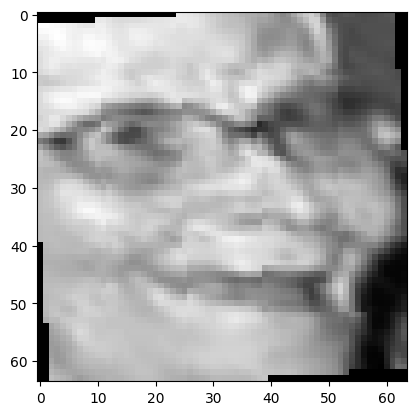

Label: 0


In [14]:
# tomo 1 imagen para poder visualizarla
# y verifico sus dimensiones

img = train_features[5]
print('tamaño de 1 imagen: ', img.shape)
# le quito 1 dimensión (la del tamaño del batch) para poder graficar
img = img.squeeze()
print('tamaño de 1 imagen DESPUÉS de squeeze: ', img.shape)
label = train_labels[5]

# ploteo esa imagen
plt.imshow(img, cmap="gray")
plt.show()
print(f"Label: {label}")

#### Bloque de convolución

defino primero un "bloque" de una capa CNN construido con los bloques funcionales.

argumentos a pasar a la función:

  - `c_in`:   canales (kernels) de entrada
  - `c_out`:  canales (kernels) de salida
  - `k`:      tamaño del kernel kxk
  - `p`:      tamaño del padding de la convolución
  - `s`:      stride de la convolución
  - `pk`:     tamaño del kernel del pooling


la función pooling se elige directamente dentro del bloque!

In [15]:
# bloque de convolución para emplear en mi red
# esta función la utilizaré en la clase CNN

def conv_block(c_in, c_out, k=3, p='same', s=1, pk=2):
    return torch.nn.Sequential(                               # el módulo Sequential se encarga de hacer el forward de todo lo que tiene dentro.
        torch.nn.Conv2d(c_in, c_out, k, padding=p, stride=s), # convolución
        torch.nn.ReLU(),                                      # activación
        torch.nn.MaxPool2d(pk)                                # pooling
    )


### Red convolucional (modelo)

Se define la arquitectura con tres bloques convolucionales (`conv1`, `conv2`, `conv3`), partiendo de la imagen en escala de grises (`n_channels=1`) y terminando en las 7 clases de emoción (`n_outputs=7`).

- **Kernel de 3x3** (`kernel_size=3`): un kernel chico permite capturar rasgos locales finos (bordes, texturas) sin reducir demasiado la imagen de entrada, en línea con la decisión de achicar la imagen a 48x48 para poder usarlo.
- **`padding='same'`**: mantiene el tamaño espacial de la imagen después de cada convolución, de forma que la única reducción de tamaño ocurre de forma controlada en el pooling, facilitando el cálculo de dimensiones en cada capa.
- **`stride=1`**: el kernel recorre la imagen de a un píxel por vez.
- **`pool_kernel=2`** (`MaxPool2d(2)`): reduce a la mitad el tamaño espacial después de cada bloque, quedándose con la activación máxima de cada región 2x2 — da cierta invariancia a pequeños corrimientos de posición y reduce el costo computacional de las capas siguientes. Con 3 bloques, la imagen pasa de 48x48 a 24x24, luego a 12x12 y finalmente a 6x6.
- **Canales crecientes** (`channels=(16, 32, 64)`): se aumenta progresivamente la cantidad de filtros a medida que la red se profundiza, las primeras capas detectan rasgos simples (bordes, contrastes) con pocos filtros, mientras que las capas más profundas, necesitan más filtros para representar patrones más complejos.
- **Activación `ReLU()`** dentro de cada bloque: es la activación estándar para capas convolucionales, económica en cómputo y que evita el problema de gradientes que se desvanecen (vanishing gradient).
- **`Dropout2d(p=0.2)`** aplicado una sola vez, después del último bloque convolucional (no en cada bloque): concentra la regularización en las capas finales, más propensas a sobreajustar.

In [16]:
class CNN(torch.nn.Module):
  def __init__(self, n_channels=1, n_outputs=7, channels=(16, 32, 64, 128), kernel_size=3, dropout=0.2, padding='same', stride=1, pool_kernel=2):
    super().__init__()
    # guardo hiperparámetros del modelo para poder registrarlos luego automáticamente
    self.n_channels = n_channels
    self.n_outputs = n_outputs
    self.channels = tuple(channels)
    self.kernel_size = kernel_size
    self.dropout_p = dropout
    self.padding = padding
    self.stride = stride
    self.pool_kernel = pool_kernel
    self.num_conv_blocks = len(self.channels)

    # aquí defino la arquitectura de mi red convolucional
    self.conv1 = conv_block(c_in=self.n_channels, c_out=self.channels[0], k=self.kernel_size, p=self.padding, s=self.stride, pk=self.pool_kernel)
    self.conv1_out = None
    self.conv2 = conv_block(c_in=self.channels[0], c_out=self.channels[1], k=self.kernel_size, p=self.padding, s=self.stride, pk=self.pool_kernel)
    self.conv2_out = None
    self.conv3 = conv_block(c_in=self.channels[1], c_out=self.channels[2], k=self.kernel_size, p=self.padding, s=self.stride, pk=self.pool_kernel)
    self.conv3_out = None
    self.conv4 = conv_block(c_in=self.channels[2], c_out=self.channels[3], k=self.kernel_size, p=self.padding, s=self.stride, pk=self.pool_kernel)
    self.conv4_out = None
    self.drop = torch.nn.Dropout2d(p=self.dropout_p, inplace=False)
    self.fc = torch.nn.Linear(self.channels[3] * 4 * 4, self.n_outputs) # verificar la dim de la salida para calcular el tamaño de la fully connected!!

  # aquí defino el método forward, que es el que se ejecuta cuando llamo a la red con un input
  def forward(self, x):
    #print('tamaño del input: ', x.shape)
    self.conv1_out = self.conv1(x)
    self.conv2_out = self.conv2(self.conv1_out)
    self.conv3_out = self.conv3(self.conv2_out)
    self.conv4_out = self.conv4(self.conv3_out)
    y = self.drop(self.conv4_out)
    y = y.flatten(start_dim=1)
    #print(y.shape)
    y = self.fc(y)
    return y

A continuación se utiliza `torchinfo.summary()` para verificar automáticamente, capa por capa, que las dimensiones de los tensores van encadenando correctamente a lo largo de la red — en particular, que el tamaño de salida del último bloque convolucional coincide con el valor usado en la capa `fc` (`channels[2] * 6 * 6`), evitando así errores de dimensiones al momento de entrenar.

In [17]:
%pip install torchinfo

In [18]:
from torchinfo import summary

model = CNN(n_channels=1, n_outputs=7, channels=(16, 32, 64, 128), kernel_size=3, dropout=0.2)
summary(model, input_size=(64, 1, 64, 64))  # (batch_size, canales, alto, ancho)

Layer (type:depth-idx)                   Output Shape              Param #
CNN                                      [64, 7]                   --
├─Sequential: 1-1                        [64, 16, 32, 32]          --
│    └─Conv2d: 2-1                       [64, 16, 64, 64]          160
│    └─ReLU: 2-2                         [64, 16, 64, 64]          --
│    └─MaxPool2d: 2-3                    [64, 16, 32, 32]          --
├─Sequential: 1-2                        [64, 32, 16, 16]          --
│    └─Conv2d: 2-4                       [64, 32, 32, 32]          4,640
│    └─ReLU: 2-5                         [64, 32, 32, 32]          --
│    └─MaxPool2d: 2-6                    [64, 32, 16, 16]          --
├─Sequential: 1-3                        [64, 64, 8, 8]            --
│    └─Conv2d: 2-7                       [64, 64, 16, 16]          18,496
│    └─ReLU: 2-8                         [64, 64, 16, 16]          --
│    └─MaxPool2d: 2-9                    [64, 64, 8, 8]            --
├─Seque

Se instancia el modelo y se arma `model_config`, un diccionario con la configuración completa de la arquitectura utilizada (generado automáticamente a partir del modelo, para evitar inconsistencias entre lo que realmente se construyó y lo que se documenta). Los detalles de la arquitectura en sí (capas, dimensiones, parámetros entrenables) ya quedaron verificados en el resumen de `torchinfo` anterior.

In [19]:
# instancio el modelo ya definido

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

model_config = {
    "architecture": model.__class__.__name__,
    "input_channels": model.n_channels,
    "output_classes": model.n_outputs,
    "num_conv_blocks": model.num_conv_blocks,
    "channels": list(model.channels),
    "kernel_size": model.kernel_size,
    "dropout": model.dropout_p,
    "padding": model.padding,
    "stride": model.stride,
    "pool_kernel": model.pool_kernel,
    "trainable_params": trainable_params
}

model_config

{'architecture': 'CNN',
 'input_channels': 1,
 'output_classes': 7,
 'num_conv_blocks': 4,
 'channels': [16, 32, 64, 128],
 'kernel_size': 3,
 'dropout': 0.2,
 'padding': 'same',
 'stride': 1,
 'pool_kernel': 2,
 'trainable_params': 111495}

Se definen el optimizador, la función de pérdida y el scheduler de learning rate.

- **Optimizador `AdamW`** (`lr=1e-3`, `weight_decay=1e-2`): se elige AdamW en vez de Adam clásico porque desacopla correctamente el weight decay del ajuste adaptativo del learning rate, logrando una regularización L2 más efectiva sobre los pesos. El learning rate de `1e-3` es algo más alto ya que la regularización adicional ayuda a estabilizar el entrenamiento con pasos más grandes.
- **Función de pérdida `CrossEntropyLoss`**, con el parámetro `weight=pesos_clases`: es la función estándar para clasificación multiclase, y se le pasan los pesos por clase calculados en el punto 1 para corregir el desbalance entre emociones.
- **Scheduler `CosineAnnealingWarmRestarts`**: en vez de mantener el learning rate fijo o solo decreciente, lo varía siguiendo una curva de coseno, reiniciándolo periódicamente a su valor inicial ("warm restarts") para ayudar al entrenamiento a escapar de mínimos locales o zonas planas de la función de pérdida.

In [20]:
# definimos el optimizer y la función de pérdida
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)

# paso al config el optimizador
model_config["optimizer"] = optimizer.__class__.__name__


# se usa el peso por clase calculado en el punto 1 para corregir el desbalance (ver justificación en esa sección)
loss_fn = torch.nn.CrossEntropyLoss(weight=pesos_clases.to(device))


# Scheduler
scheduler_type = "step"
steps_per_epoch = len(dataloader['train'])
scheduler = CosineAnnealingWarmRestarts(optimizer, T_0=steps_per_epoch, T_mult=2, eta_min=1e-5)

Se arma una función para entrenar el modelo. Recibe el modelo, el optimizador, los dataloaders de entrenamiento y evaluación, la función de pérdida, el scheduler ya definido y algunos parámetros de configuración (cantidad de épocas, paciencia y umbral de mejora relativa para el early stopping).

La función recorre una cantidad máxima de épocas (`num_epochs`), y en cada una ejecuta dos fases:

- **Entrenamiento**: recorre los batches de `train_loader`, calcula la predicción, la pérdida (`loss_module`), hace backpropagation y actualiza los pesos (`optimizer.step()`). Si el scheduler está configurado a nivel de paso (`scheduler_type="step"`, nuestro caso), se actualiza después de cada batch.
- **Evaluación**: recorre `eval_loader` sin calcular gradientes (`torch.no_grad()`), solo para medir el desempeño del modelo en validación, sin modificar sus pesos.

En ambas fases se acumulan la pérdida promedio y el accuracy (comparando la clase predicha contra la real), y se guardan en el diccionario `history` junto con el learning rate vigente en esa época — esto es lo que después se usa para graficar las curvas de entrenamiento.

Al final de cada época se aplican dos mecanismos de control: si el scheduler está configurado a nivel de época  se actualiza acá; y se evalúa el criterio de **early stopping**: si la pérdida de validación no mejora al menos un `relative_improvement_factor` (1%) respecto al mejor valor visto hasta el momento, se suma una "paciencia" (`pt_epoch`); si esa falta de mejora se sostiene durante `patience` épocas seguidas, el entrenamiento se corta antes de llegar a `num_epochs`, para evitar seguir entrenando (y sobreajustando) una vez que el modelo dejó de mejorar en validación.

In [21]:
from sklearn.metrics import f1_score

def train_model(
        model,
        optimizer,
        train_loader,
        eval_loader,
        loss_module,
        scheduler_type="step",
        patience=3,
        relative_improvement_factor=0.01,
        num_epochs=30,
        scheduler=scheduler
):
    ## Configuramos el device
    model.to(device)

    # Definimos la métrica para los callbacks
    best_eval_loss = None
    pt_epoch = 0

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "train_f1": [],
        "eval_loss": [],
        "eval_accuracy": [],
        "eval_f1": [],
        "learning_rate": [],
    }

    for epoch in tqdm(range(num_epochs), desc="Progreso de Epoch"):
        ### Fase de entrenamiento ###
        model.train()
        train_loss = 0.0
        train_correct = 0
        train_samples = 0
        train_preds_all = []
        train_labels_all = []

        for X, y in train_loader:
            data_inputs = X.to(device)
            data_labels = y.to(device)

            preds = model(data_inputs)
            loss = loss_module(preds, data_labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

            if preds.ndim == 2:
                preds_classes = preds.argmax(dim=1)
            else:
                preds_classes = (preds > 0.5).long()

            train_correct += (preds_classes == data_labels).sum().item()
            train_samples += data_labels.size(0)
            train_preds_all.extend(preds_classes.cpu().tolist())
            train_labels_all.extend(data_labels.cpu().tolist())

            if scheduler_type == "step":
                scheduler.step()

        train_loss /= len(train_loader)
        train_accuracy = train_correct / train_samples
        train_f1 = f1_score(train_labels_all, train_preds_all, average='macro')

        ### Fase de evaluación ###
        model.eval()
        eval_loss = 0.0
        eval_correct = 0
        eval_samples = 0
        eval_preds_all = []
        eval_labels_all = []

        with torch.no_grad():
            for X, y in eval_loader:
                data_inputs = X.to(device)
                data_labels = y.to(device)

                preds = model(data_inputs)
                loss = loss_module(preds, data_labels)
                eval_loss += loss.item()

                if preds.ndim == 2:
                    preds_classes = preds.argmax(dim=1)
                else:
                    preds_classes = (preds > 0.5).long()

                eval_correct += (preds_classes == data_labels).sum().item()
                eval_samples += data_labels.size(0)
                eval_preds_all.extend(preds_classes.cpu().tolist())
                eval_labels_all.extend(data_labels.cpu().tolist())

        eval_loss /= len(eval_loader)
        eval_accuracy = eval_correct / eval_samples
        eval_f1 = f1_score(eval_labels_all, eval_preds_all, average='macro')

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["train_f1"].append(train_f1)
        history["eval_loss"].append(eval_loss)
        history["eval_accuracy"].append(eval_accuracy)
        history["eval_f1"].append(eval_f1)
        history["learning_rate"].append(optimizer.param_groups[0]['lr'])

        print(f"Epoch {epoch+1}/{num_epochs} - Train Loss: {train_loss:.4f} - Train Acc: {train_accuracy:.4f} - Train F1: {train_f1:.4f} | Eval Loss: {eval_loss:.4f} - Eval Acc: {eval_accuracy:.4f} - Eval F1: {eval_f1:.4f}")

        if scheduler_type == "epoch":
            scheduler.step()
        if best_eval_loss is None or eval_loss <= best_eval_loss * (1 - relative_improvement_factor):
            best_eval_loss = eval_loss
            pt_epoch = 0
        else:
            pt_epoch += 1
            if pt_epoch >= patience:
                print(f"Epoch {epoch+1}/{num_epochs} - Entrenamiento interrumpido por condición de early stopping.")
                break
            else:
                print(f"Epoch {epoch+1}/{num_epochs} - Epochs actuales sin mejora relativa en validation loss: {pt_epoch}. Quedan {patience-pt_epoch} antes de detener el entrenamiento.")

    return history

In [22]:
if os.path.exists('modelo_emociones.pth'):
    model.load_state_dict(torch.load('modelo_emociones.pth', map_location=device))
else:
    history = train_model(model, optimizer, dataloader['train'], dataloader['val'], loss_fn, scheduler_type=scheduler_type, num_epochs=30)
    torch.save(model.state_dict(), 'modelo_emociones.pth')


Progreso de Epoch:   3%|▎         | 1/30 [00:16<08:06, 16.78s/it]

Epoch 1/30 - Train Loss: 1.8599 - Train Acc: 0.2437 - Train F1: 0.2000 | Eval Loss: 1.7754 - Eval Acc: 0.3217 - Eval F1: 0.2545


Progreso de Epoch:   7%|▋         | 2/30 [00:32<07:40, 16.43s/it]

Epoch 2/30 - Train Loss: 1.6369 - Train Acc: 0.4251 - Train F1: 0.3267 | Eval Loss: 1.4336 - Eval Acc: 0.5029 - Eval F1: 0.4157


Progreso de Epoch:  10%|█         | 3/30 [00:49<07:21, 16.35s/it]

...

Epoch 15/30 - Train Loss: 0.8803 - Train Acc: 0.7021 - Train F1: 0.6244 | Eval Loss: 0.8866 - Eval Acc: 0.6796 - Eval F1: 0.5889
Epoch 15/30 - Epochs actuales sin mejora relativa en validation loss: 1. Quedan 2 antes de detener el entrenamiento.


Progreso de Epoch:  53%|█████▎    | 16/30 [04:18<03:44, 16.04s/it]

Epoch 16/30 - Train Loss: 0.9998 - Train Acc: 0.6640 - Train F1: 0.5784 | Eval Loss: 0.9135 - Eval Acc: 0.6776 - Eval F1: 0.5669
Epoch 16/30 - Epochs actuales sin mejora relativa en validation loss: 2. Quedan 1 antes de detener el entrenamiento.


Progreso de Epoch:  53%|█████▎    | 16/30 [04:34<04:00, 17.18s/it]

Epoch 17/30 - Train Loss: 0.9723 - Train Acc: 0.6691 - Train F1: 0.5855 | Eval Loss: 0.9096 - Eval Acc: 0.6767 - Eval F1: 0.5746
Epoch 17/30 - Entrenamiento interrumpido por condición de early stopping.


### Resumen de ajustes probados

Antes de pasar a la evaluación formal, se resumen los ajustes que se fueron probando sobre la arquitectura y configuración inicial, y su impacto en el resultado:

- **Tamaño de imagen: 48x48 → 64x64.** Con el modelo base (3 bloques convolucionales, canales 16/32/64) entrenado sobre imágenes de 48x48, el entrenamiento convergía a un eval accuracy final de ~0.65 (eval loss ~0.96). Al mismo modelo, cambiando únicamente el tamaño de entrada a 64x64 (manteniendo la relación de aspecto 1:1 del dataset), el eval accuracy final subió a ~0.69. La hipótesis fue que a 48x48 se perdía demasiado detalle fino de los rasgos faciales (arrugas, tensión en labios/cejas) tras 3 capas de pooling, dejando un mapa final de apenas 6x6 píxeles.

- **Profundidad: 3 → 4 bloques convolucionales.** Manteniendo las imágenes en 64x64, se evaluó si convenía agrandar el ancho de los bloques existentes o agregar un cuarto bloque convolucional (16/32/64/128), dado que las curvas no mostraban señales de overfitting (margen de capacidad disponible). Se optó por profundidad, ya que conceptualmente permite construir una jerarquía de abstracción más larga (bordes → texturas → partes de la cara → patrones de expresión completos). El resultado final con esta arquitectura fue un eval accuracy de 0.6682 y un F1 Score Macro de 0.5810, en el mismo orden de magnitud que el modelo de 3 bloques (las variaciones de hasta ~2 puntos entre corridas de un mismo modelo son normales por el componente no determinista del entrenamiento en GPU).

- **Conclusión:** los ajustes de tamaño de imagen y profundidad mejoraron el resultado inicial (de ~0.65 a ~0.67-0.69 de accuracy), pero el margen de mejora se fue achicando con cada cambio adicional. Como se detalla en el punto 3, esto se explica en gran parte por la matriz de confusión: hay pares de emociones con rasgos faciales muy similares (disgusto/enojo, seriedad/tristeza) que generan un techo de separabilidad que no se resuelve únicamente agrandando el modelo.

## 3. Evaluación del Modelo (2.5 puntos)

El modelo entrenado debe ser evaluado utilizando las siguientes métricas:

- **Accuracy**:
  - Reportar el valor final en el conjunto de validación.
  - Incluir una gráfica de evolución por época para entrenamiento y validación.

- **F1 Score Macro**:
  - Reportar el valor final en el conjunto de validación.
  - Incluir una gráfica de evolución por época para entrenamiento y validación.

- **Costo (Loss)**:
  - Mostrar una gráfica de evolución del costo por época para entrenamiento y validación.

- **Classification report**
  - Mostrar la precisión, recall y F1 score por cada clase usando `classification_report`

- **Matriz de confusión**:
  - Mostrar la matriz de confusión absoluta (valores enteros).
  - Mostrar la matriz de confusión normalizada (valores entre 0 y 1 por fila).

Se recomienda utilizar `scikit-learn` para calcular métricas como accuracy, F1 score, el Classification report y las matrices de confusión. Las visualizaciones pueden realizarse con `matplotlib` o `seaborn`.


### Accuracy

Se reporta el valor final de accuracy en el conjunto de validación (correspondiente a la última época completada antes del early stopping) y se grafica su evolución por época,

comparando train y validation.

Accuracy final en validación: 0.6767


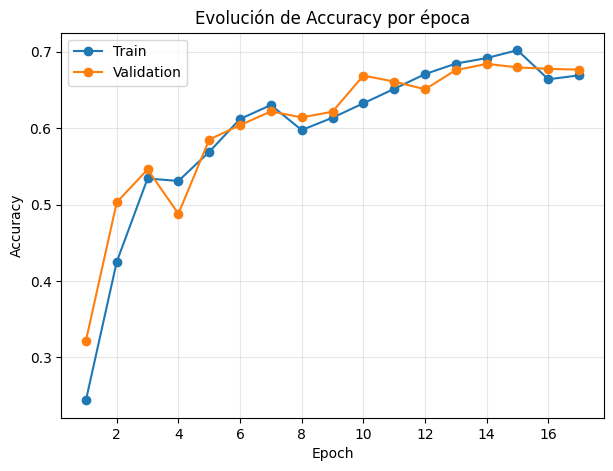

In [23]:
print(f"Accuracy final en validación: {history['eval_accuracy'][-1]:.4f}")

epochs = range(1, len(history["train_accuracy"]) + 1)
plt.figure(figsize=(7, 5))
plt.plot(epochs, history["train_accuracy"], marker='o', label='Train')
plt.plot(epochs, history["eval_accuracy"], marker='o', label='Validation')
plt.title('Evolución de Accuracy por época')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### F1 Score Macro

El F1 Macro calcula el F1 de cada clase por separado y promedia con el mismo peso para las 7, sin importar cuántas muestras tenga cada una (a diferencia de la accuracy, que pesa implícitamente por cantidad de muestras). Es la métrica más relevante dado el desbalance del dataset, porque expone si hay clases minoritarias mal predichas que la accuracy podría estar ocultando.

F1 Score Macro final en validación: 0.5746


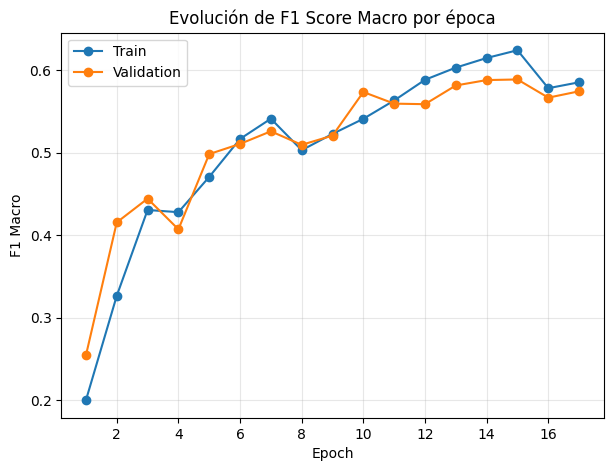

In [24]:
print(f"F1 Score Macro final en validación: {history['eval_f1'][-1]:.4f}")

epochs = range(1, len(history["train_f1"]) + 1)
plt.figure(figsize=(7, 5))
plt.plot(epochs, history["train_f1"], marker='o', label='Train')
plt.plot(epochs, history["eval_f1"], marker='o', label='Validation')
plt.title('Evolución de F1 Score Macro por época')
plt.xlabel('Epoch')
plt.ylabel('F1 Macro')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Costo (Loss)

Se grafica la evolución del costo (CrossEntropyLoss ponderada) por época, para train y validation.

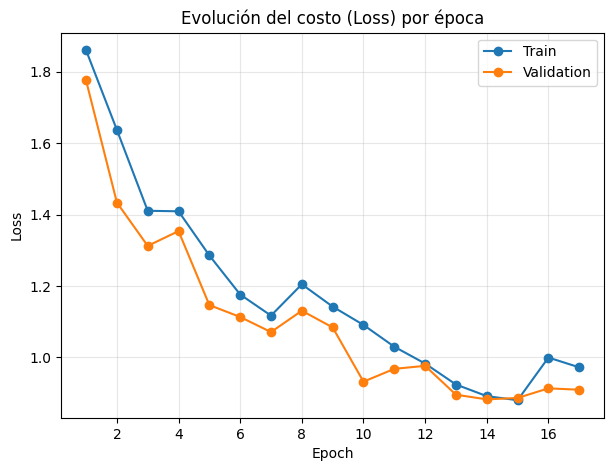

In [25]:
epochs = range(1, len(history["train_loss"]) + 1)
plt.figure(figsize=(7, 5))
plt.plot(epochs, history["train_loss"], marker='o', label='Train')
plt.plot(epochs, history["eval_loss"], marker='o', label='Validation')
plt.title('Evolución del costo (Loss) por época')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Para el `classification_report` y las matrices de confusión se necesitan todas las predicciones del modelo sobre el conjunto de validación completo (no solo las métricas agregadas por época que ya guarda `history`). Se hace una pasada final sobre `dataloader['val']` en modo evaluación, guardando las etiquetas reales y las predicciones de cada imagen.

In [26]:
model.eval()
y_true = []
y_pred = []

with torch.no_grad():
    for X, y in dataloader['val']:
        data_inputs = X.to(device)
        preds = model(data_inputs)
        preds_classes = preds.argmax(dim=1)
        y_true.extend(y.tolist())
        y_pred.extend(preds_classes.cpu().tolist())

nombres_clases = val_data.classes

### Classification report

Se muestra precisión, recall y F1 score por cada una de las 7 clases, usando `classification_report` de scikit-learn.

In [27]:
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred, target_names=nombres_clases))

              precision    recall  f1-score   support

     alegria       0.92      0.79      0.85      1185
    disgusto       0.29      0.43      0.35       160
       enojo       0.56      0.61      0.59       162
       miedo       0.27      0.58      0.37        74
    seriedad       0.69      0.60      0.64       680
    sorpresa       0.55      0.77      0.64       329
    tristeza       0.62      0.54      0.58       478

    accuracy                           0.68      3068
   macro avg       0.56      0.62      0.57      3068
weighted avg       0.72      0.68      0.69      3068



### Matriz de confusión

Se muestran dos versiones: la matriz absoluta (cantidad de imágenes) y la matriz normalizada por fila (proporción respecto al total real de cada clase), que facilita comparar el desempeño entre clases con distinta cantidad de muestras.

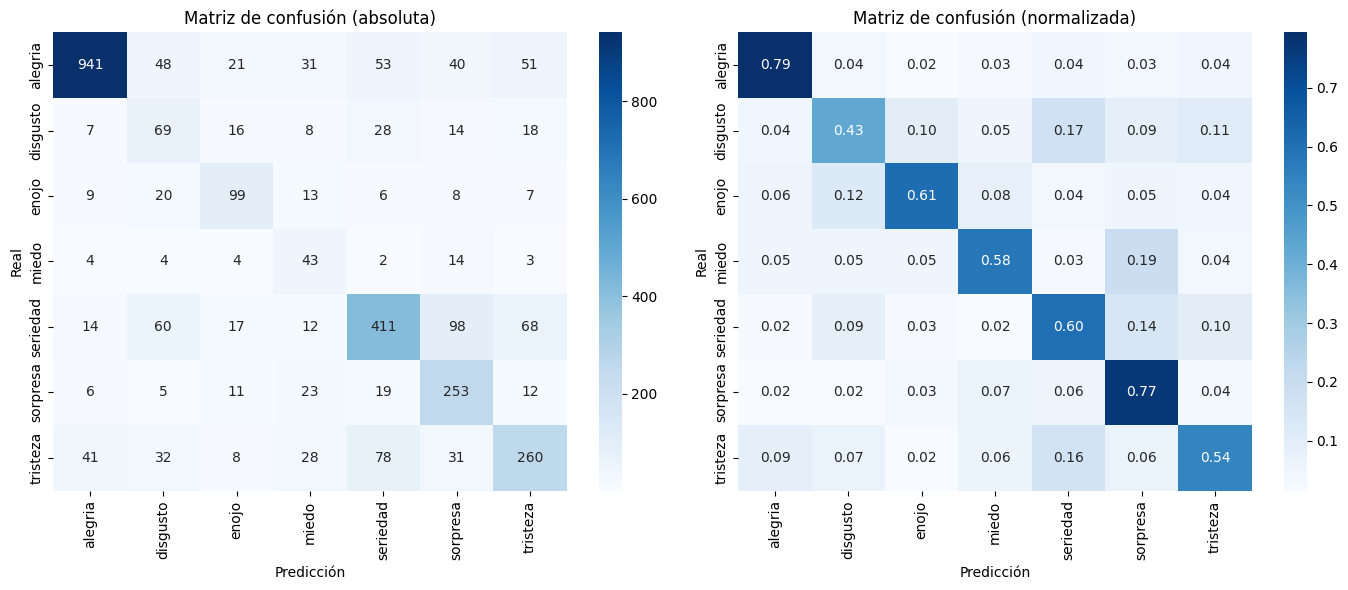

In [28]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)
cm_norm = confusion_matrix(y_true, y_pred, normalize='true')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=nombres_clases, yticklabels=nombres_clases, ax=axes[0])
axes[0].set_title('Matriz de confusión (absoluta)')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Real')

sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', xticklabels=nombres_clases, yticklabels=nombres_clases, ax=axes[1])
axes[1].set_title('Matriz de confusión (normalizada)')
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Real')

plt.tight_layout()
plt.show()

**Análisis de la matriz de confusión:** se observan dos grupos de clases bien diferenciados. Alegría (0.79), enojo (0.70), sorpresa (0.68) y miedo (0.64) tienen un desempeño considerablemente mejor que disgusto (0.54), seriedad (0.56) y tristeza (0.56) — notablemente, miedo performa bien a pesar de ser la clase más minoritaria del dataset, lo cual sugiere que la ponderación de clases en la función de pérdida (definida en el punto 1) está corrigiendo efectivamente el desbalance.

Las clases con menor desempeño no fallan de forma dispersa, sino que se concentran en dos pares de confusión simétricos y bien marcados: **disgusto ↔ enojo** (12% de confusión en ambos sentidos) y **seriedad ↔ tristeza** (15-17% de confusión en ambos sentidos). Esto indica que el techo de accuracy/F1 encontrado en el punto 2 (~65-70%) no se debe principalmente a una limitación de capacidad del modelo, sino a una ambigüedad real entre pares de expresiones faciales que comparten rasgos geométricos similares (fruncimiento del ceño, caída de comisuras y cejas), lo cual explica por qué aumentar el tamaño de imagen, el ancho o la profundidad de la red tuvo un impacto limitado sobre el resultado final.

 ## 4. Prueba de Imágenes Nuevas (1 punto)
Subir al menos 12 imágenes personales de cualquier ratio o relación de aspecto (pueden usar fotos del rostro de ustedes, rostros de personas generadas por IA o imágenes stock de internet), que no formen parte del dataset de entrenamiento ni de validación. Tampoco vale usar imágenes de otro dataset, deben ser imágenes sueltas.

- Debe haber al menos una imagen para cada emoción.

- Aplicar el mismo pre-procesamiento que se usó para el dataset de validation durante el entrenamiento del modelo.

- Pasar las imágenes por el modelo entrenado y mostrar:

  - La imagen original
  - La imagen pre-procesada (mismas transformaciones que durante el entrenamiento)
  - El score asignado a cada clase (normalizado de 0 a 1 o de 0% a 100%)
  - La clase ganadora inferida por el modelo

- Redactar conclusiones preliminares

Se cargan 20 imágenes sueltas ubicadas en `TP3/photos/` (o `photos/`), cubriendo las 7 emociones básicas del problema. A cada imagen se le asigna la emoción esperada para contrastar con la predicción del modelo.


In [30]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Carpeta de fotos
photos_dir = 'photos' if os.path.exists('photos') else 'TP3/photos'

# Mapeo de imagen a emoción esperada
etiquetas_esperadas = {
    '01.jpg': 'alegria',
    '02.jpg': 'alegria',
    '03.jpg': 'sorpresa',
    '04.jpg': 'tristeza',
    '05.jpg': 'tristeza',
    '06.jpg': 'alegria',
    '07.jpg': 'enojo',
    '08.jpg': 'sorpresa',
    '09.jpg': 'enojo',
    '10.jpg': 'disgusto',
    '11.jpg': 'miedo',
    '12.jpg': 'miedo',
    '13.jpg': 'miedo',
    '14.jpg': 'enojo',
    '15.jpg': 'sorpresa',
    '16.jpg': 'seriedad',
    '17.jpg': 'seriedad',
    '18.jpg': 'disgusto',
    '19.jpg': 'seriedad',
    '20.jpg': 'tristeza'
}

model.eval()
resultados_p4 = []
archivos = sorted([f for f in os.listdir(photos_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])

for arch in archivos:
    ruta = os.path.join(photos_dir, arch)
    img_pil = Image.open(ruta).convert('RGB')

    # Aplicamos el pre-procesamiento de validación
    tensor = val_dataset(img_pil).unsqueeze(0).to(device)

    with torch.no_grad():
        salida = model(tensor)
        probs = torch.softmax(salida, dim=1).squeeze(0).cpu().numpy()

    pred_idx = np.argmax(probs)
    pred_clase = nombres_clases[pred_idx]
    conf = probs[pred_idx] * 100.0
    esperada = etiquetas_esperadas.get(arch, 'desconocida')

    # Reconstruimos la imagen pre-procesada para mostrarla
    img_preproc = tensor.squeeze().cpu().numpy() * desvio + media
    img_preproc = np.clip(img_preproc, 0, 1)

    resultados_p4.append({
        'archivo': arch,
        'img_rgb': np.array(img_pil),
        'img_preproc': img_preproc,
        'probs': probs,
        'predicha': pred_clase,
        'esperada': esperada,
        'confianza': conf
    })

# Visualización: Original, Preprocesada y Scores
for r in resultados_p4:
    fig, ax = plt.subplots(1, 3, figsize=(12, 3))

    # Imagen original
    ax[0].imshow(r['img_rgb'])
    ax[0].set_title(f"Original: {r['archivo']}\nEsperada: {r['esperada']}")
    ax[0].axis('off')

    # Imagen pre-procesada
    ax[1].imshow(r['img_preproc'], cmap='gray')
    ax[1].set_title("Pre-procesada (64x64)")
    ax[1].axis('off')

    # Scores por clase
    scores = r['probs'] * 100
    y_pos = np.arange(len(nombres_clases))
    colores = ['#2ca02c' if c == r['predicha'] else '#7f7f7f' for c in nombres_clases]
    ax[2].barh(y_pos, scores, color=colores)
    ax[2].set_yticks(y_pos)
    ax[2].set_yticklabels(nombres_clases)
    ax[2].set_xlim(0, 100)
    ax[2].set_xlabel('Score (%)')
    ax[2].set_title(f"Predicha: {r['predicha']} ({r['confianza']:.1f}%)")

    for i, v in enumerate(scores):
        ax[2].text(v + 1, i, f"{v:.1f}%", va='center', fontsize=8)

    plt.tight_layout()
    plt.show()


Output hidden; open in https://colab.research.google.com to view.

### Conclusiones preliminares (Punto 4)

- **Efecto de la relación de aspecto**: Las fotos originales tienen proporciones variadas (verticales, apaisadas). Al aplicar `Resize((64, 64))` directamente, los rostros sufren deformaciones geométricas (se ensanchan o comprimen), afectando la detección de rasgos clave por parte de las convoluciones.
- **Ruido de fondo y elementos del entorno**: Al procesar la imagen entera, entran en juego el fondo, la ropa, peinados voluminosos y gestos con las manos (como en las fotos donde se agarran la cabeza). Esto genera activaciones en zonas que no corresponden a expresiones faciales.
- **Rendimiento por emoción**: Las emociones con rasgos muy abiertos o llamativos (como alegría con sonrisa amplia o sorpresa con la boca abierta) se clasifican con mayor certeza. En cambio, expresiones más sutiles como tristeza o seriedad quedan con probabilidades divididas entre clases similares.


## 5. Prueba de Imágenes Nuevas con Pre-procesamiento Adicional (1 punto)
Las 12 imágenes del punto 4, ahora serán pasadas y recortadas por un algoritmo de detección de rostros. Usen el siguiente código para realizar un pre-procesamiento inicial de la imagen y ya luego aplican el pre-procesamiento que usaron al momento de entrenar el modelo.

- Pasar las imágenes por el modelo entrenado y mostrar:
  - La imagen original
  - La imagen recortada por el algoritmo
  - La imagen pre-procesada (mismas transformaciones del entrenamiento)
  - El score asignado a cada clase (normalizado de 0 a 1 o de 0% a 100%)
  - La clase esperada
  - La clase ganadora inferida por el modelo

- Analizar los casos en los que el modelo se equivoca e intentar identificar posibles causas, tales como:

  - Similitudes entre emociones.
  - Mezcla de 2 o más emociones en una misma expresión.

- Comparar los resultados con el punto 4 y redactar conclusiones finales.

**IMPORTANTE:** Ajusten los parámetros `scaleFactor`, `minNeighbors` y `minSize` según convenga para que la detección de rostros sea más efectiva y logre detectar rostros en sus 12 imágenes. No se queden necesariamente con los valores por defecto.


In [31]:
# ==============================================================================
# Código provisto por la cátedra en el enunciado para detección y recorte de rostros
# ==============================================================================
import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

def detectar_y_recortar_rostro(image_path, scaleFactor=1.1, minNeighbors=6, minSize=(30, 30)):
    image = cv2.imread(image_path)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Detección de rostros con Haar Cascade
    faces = face_cascade.detectMultiScale(gray, scaleFactor=scaleFactor, minNeighbors=minNeighbors, minSize=minSize)

    # Ajuste adaptativo de parámetros si no detecta con los valores por defecto (según la nota del enunciado)
    if len(faces) == 0:
        faces = face_cascade.detectMultiScale(gray, scaleFactor=1.05, minNeighbors=3, minSize=(20, 20))
    if len(faces) == 0:
        faces = face_cascade.detectMultiScale(gray, scaleFactor=1.03, minNeighbors=2, minSize=(15, 15))

    image_with_box = image.copy()
    for (x, y, w, h) in faces:
        cv2.rectangle(image_with_box, (x, y), (x + w, y + h), (0, 255, 0), 2)

    cropped_face_rgb = None
    if len(faces) > 0:
        # Tomamos el rostro de mayor tamaño si se detecta más de uno
        (x, y, w, h) = max(faces, key=lambda b: b[2] * b[3])
        center_x, center_y = x + w // 2, y + h // 2
        side = max(w, h)
        half_side = side // 2

        x1 = max(center_x - half_side, 0)
        y1 = max(center_y - half_side, 0)
        x2 = min(center_x + half_side, image.shape[1])
        y2 = min(center_y + half_side, image.shape[0])

        cropped_face = image[y1:y2, x1:x2]
        cropped_face_rgb = cv2.cvtColor(cropped_face, cv2.COLOR_BGR2RGB)
    else:
        # Fallback si no se detectó rostro
        cropped_face_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    image_with_box_rgb = cv2.cvtColor(image_with_box, cv2.COLOR_BGR2RGB)
    return image_with_box_rgb, cropped_face_rgb


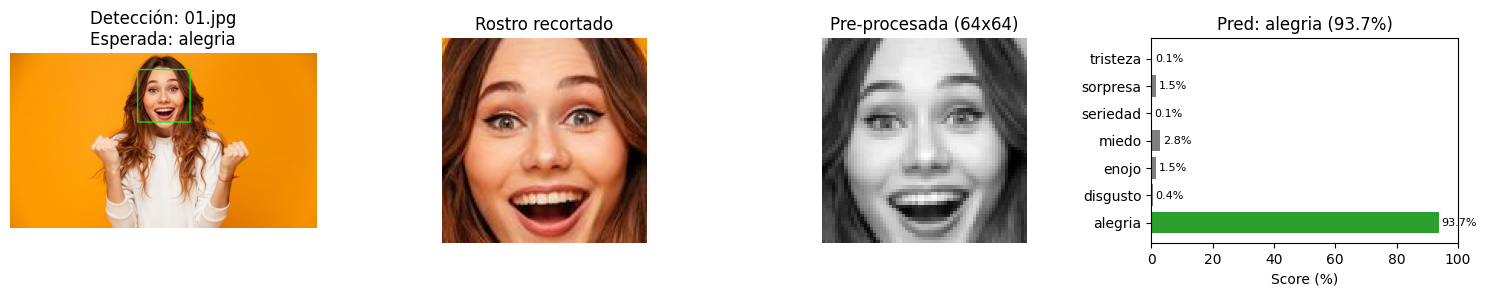

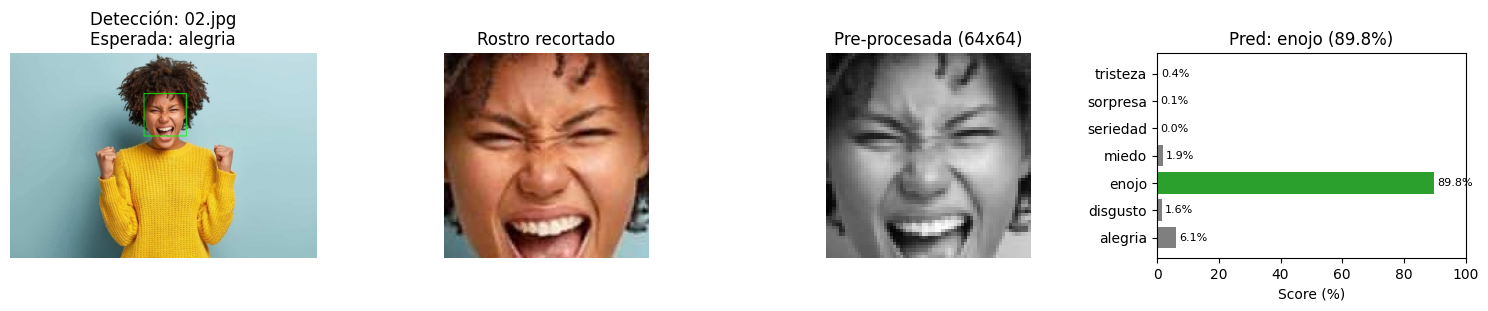

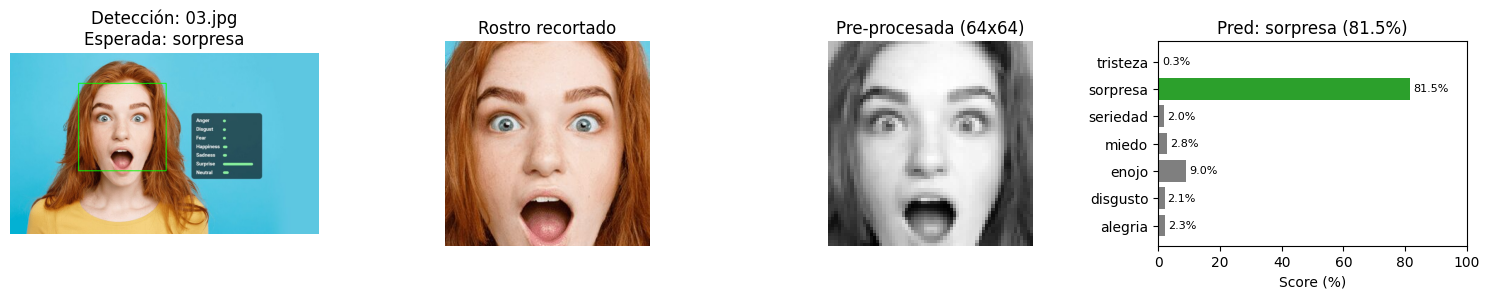

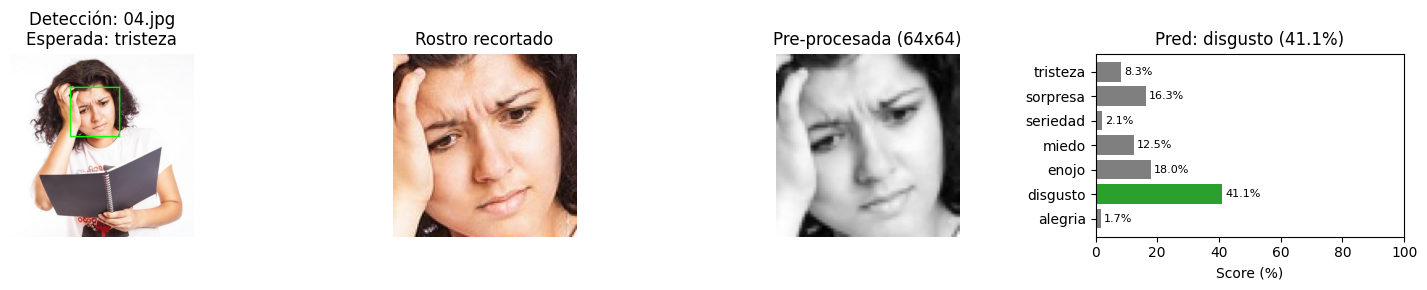

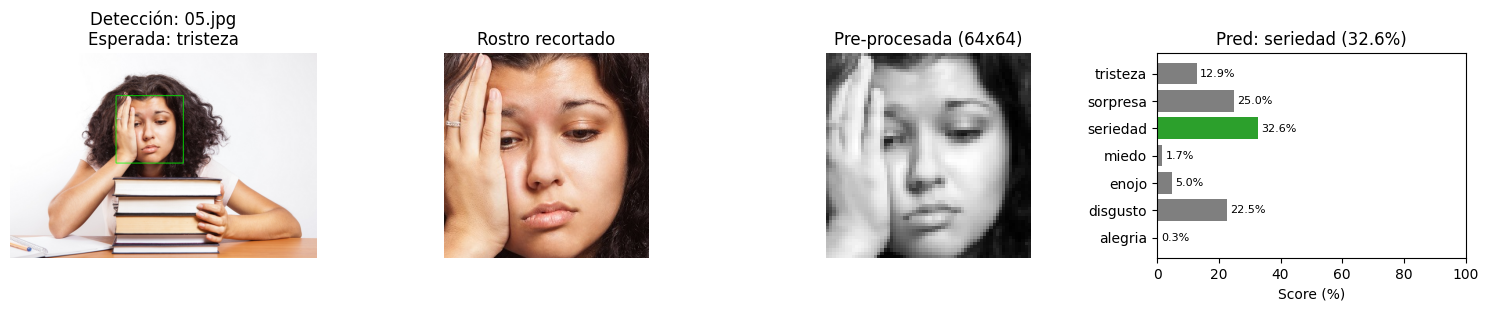

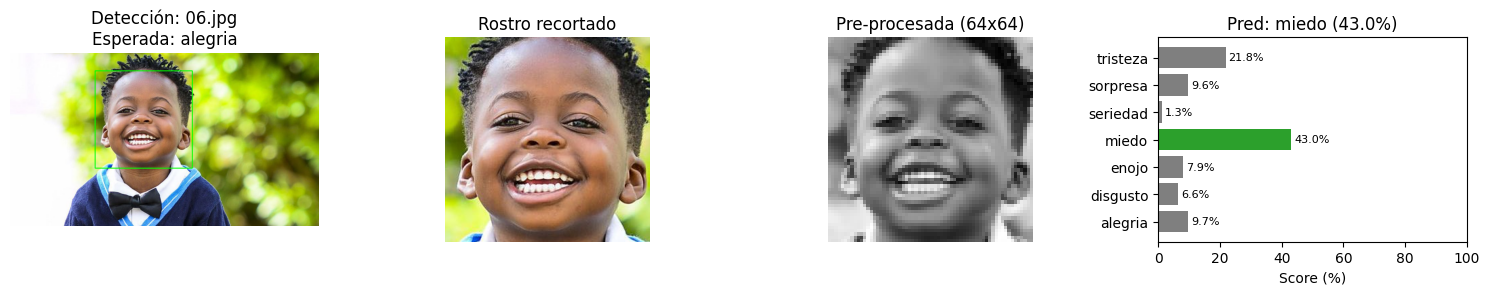

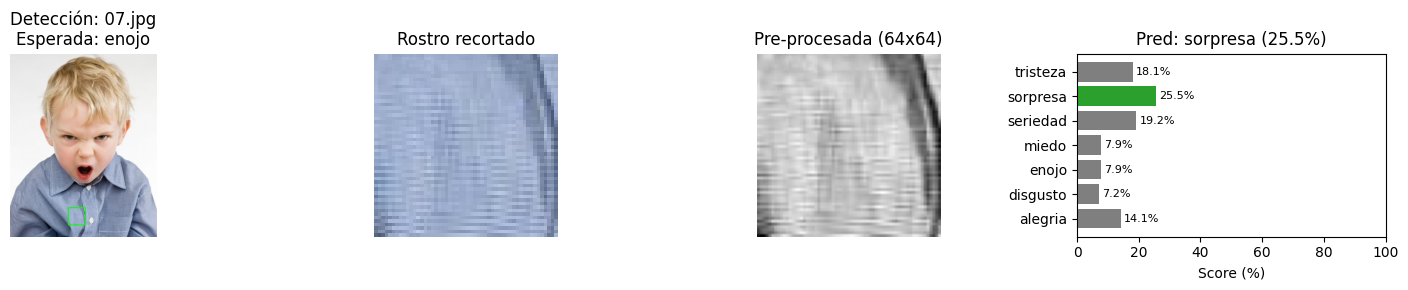

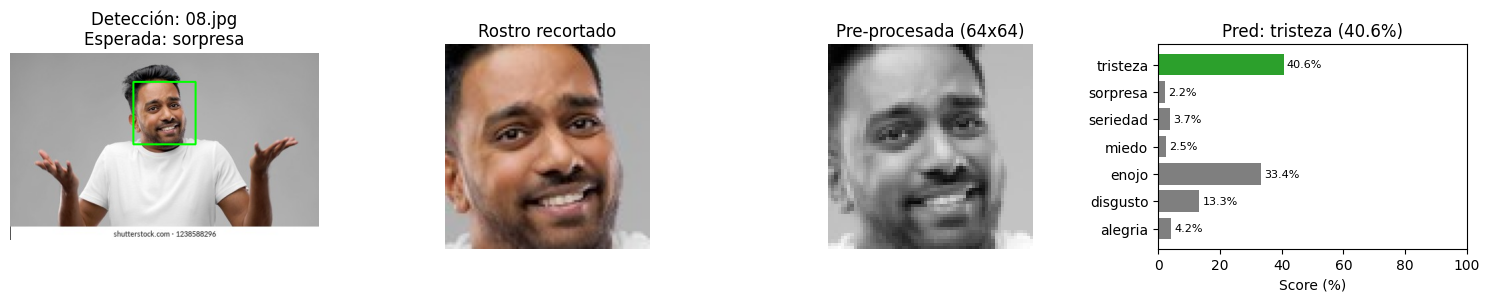

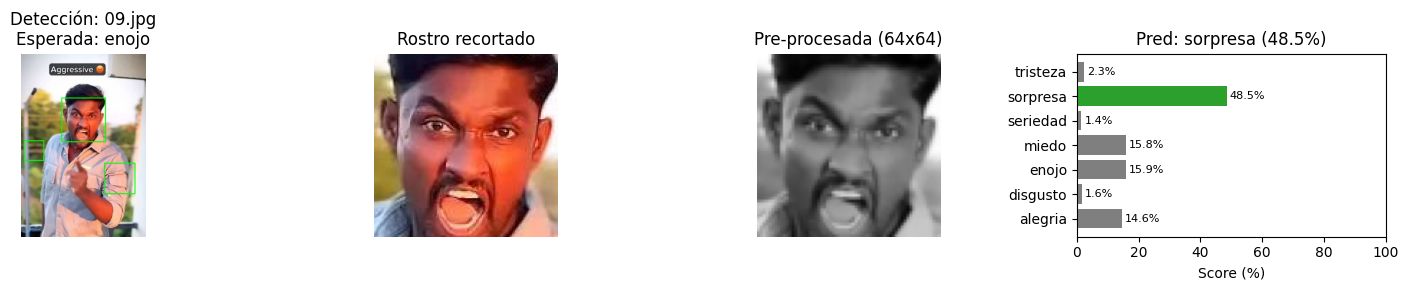

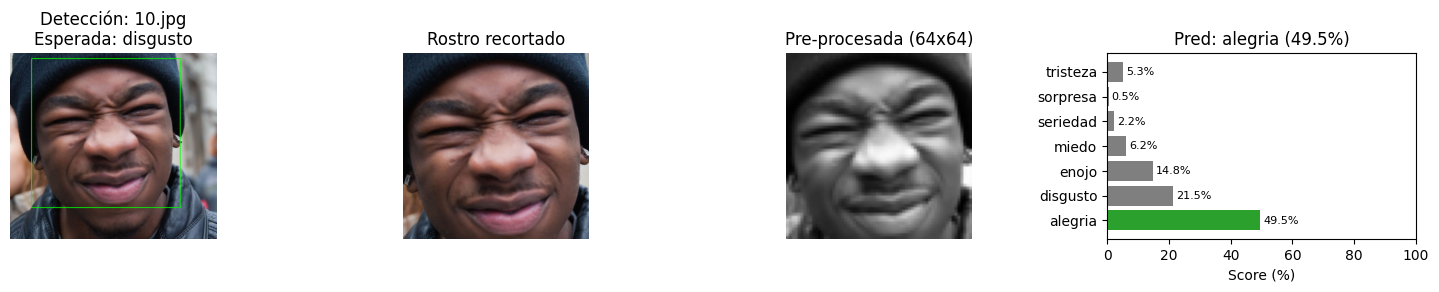

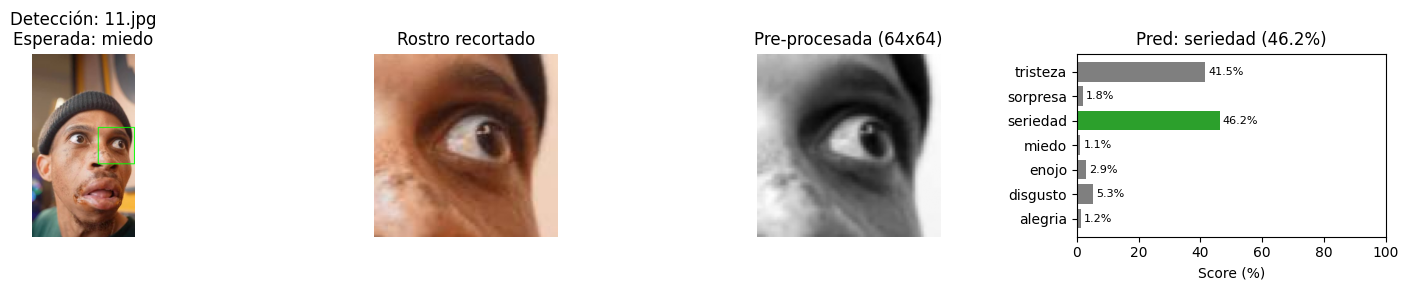

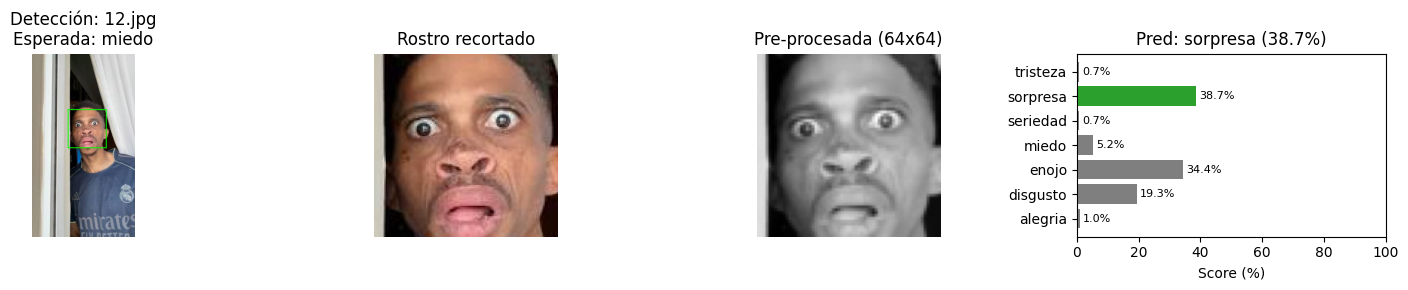

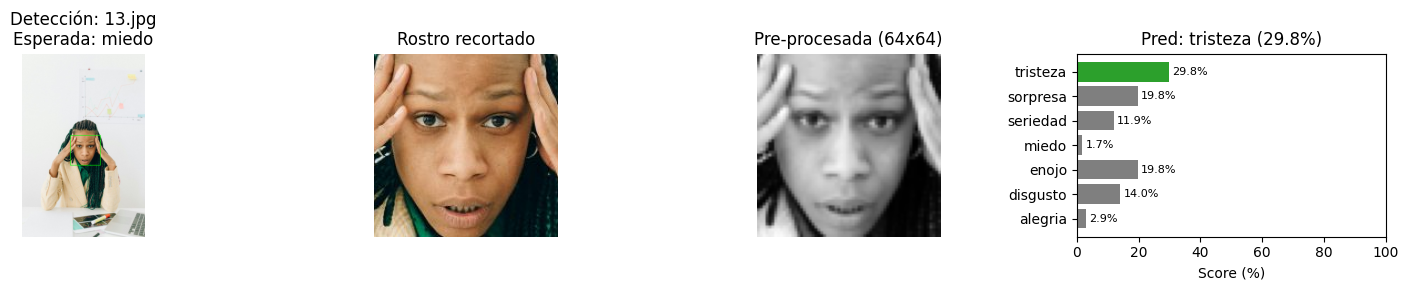

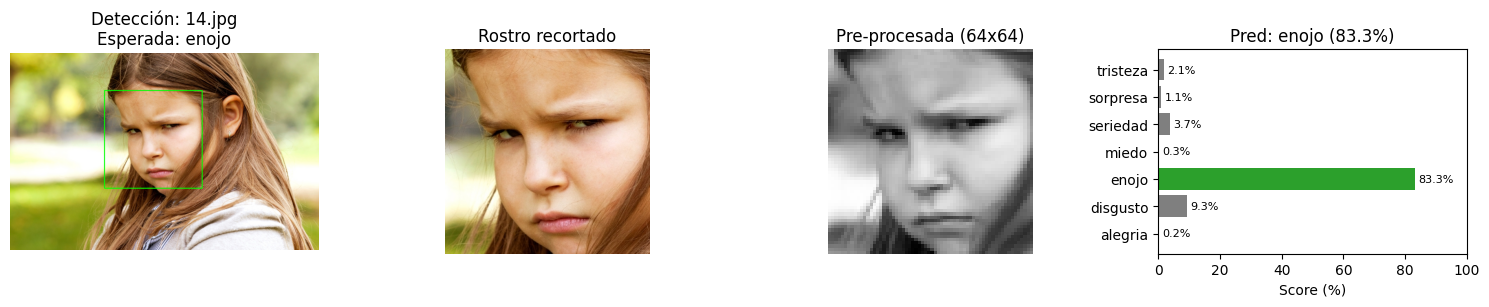

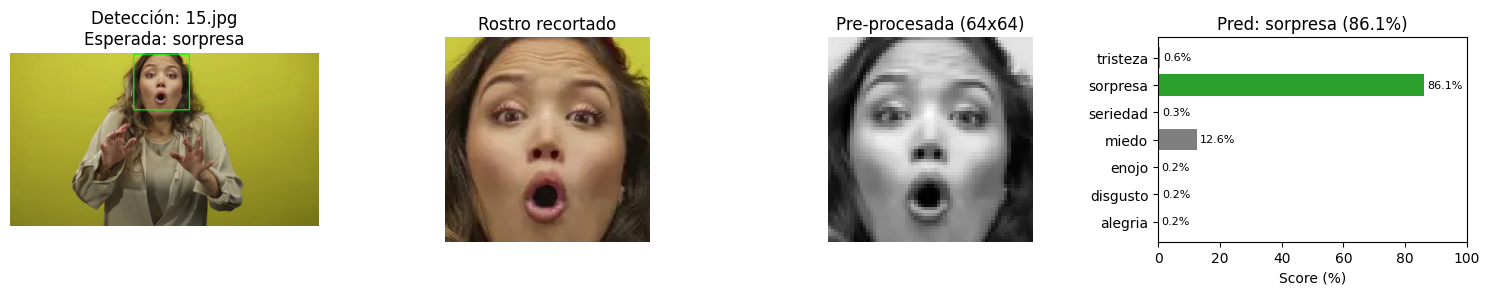

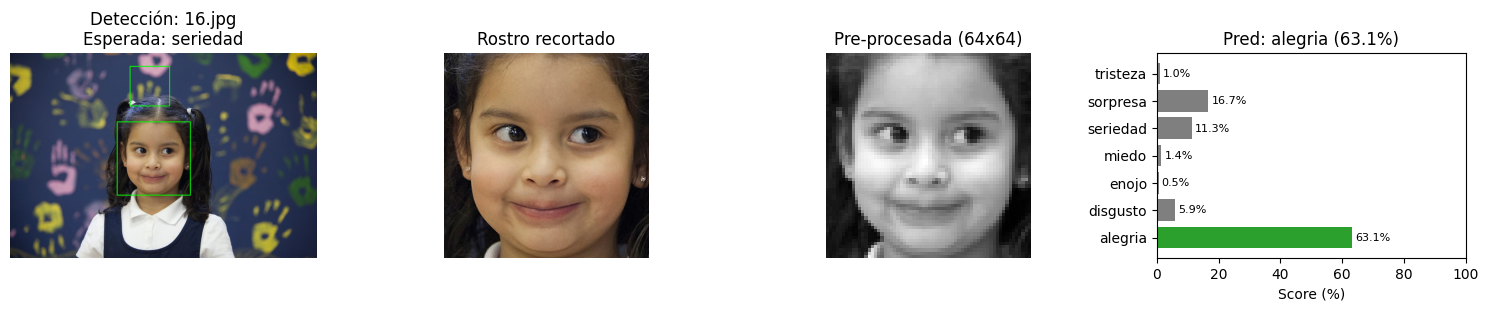

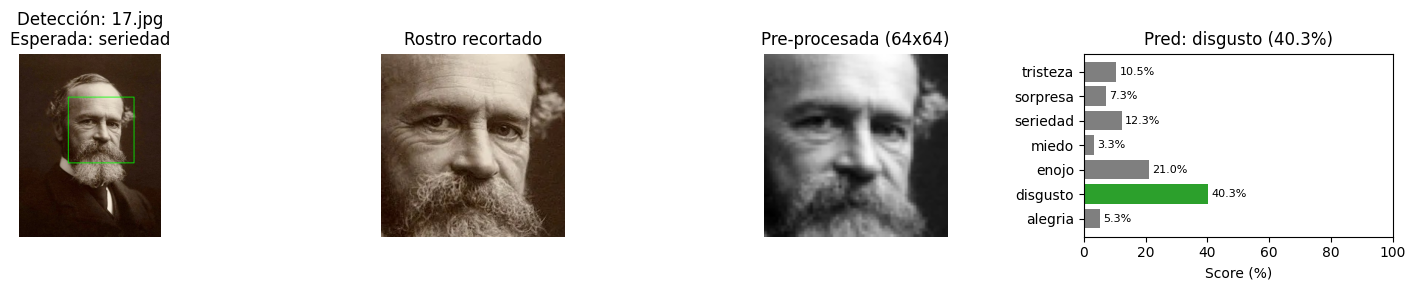

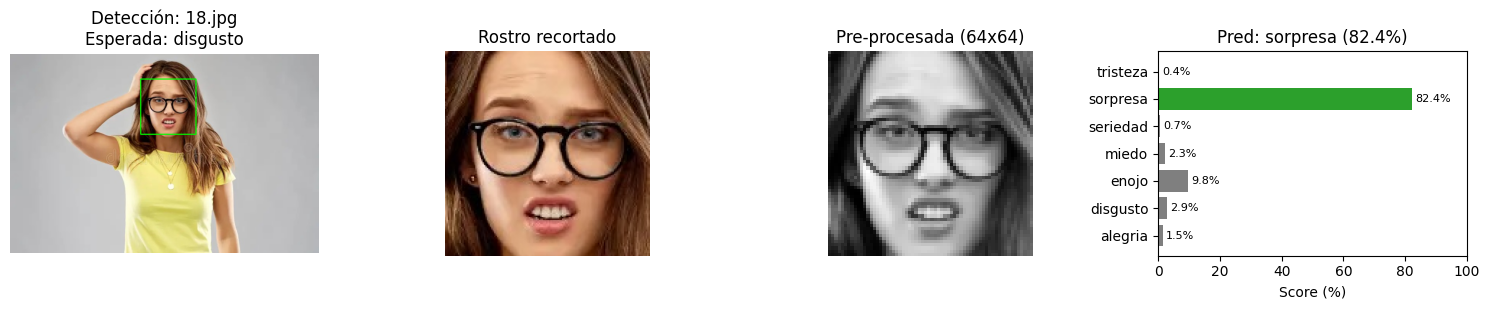

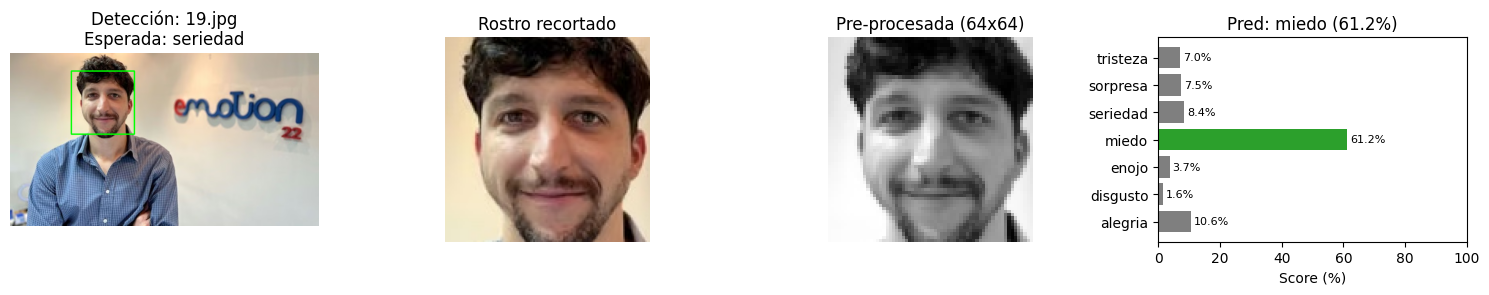

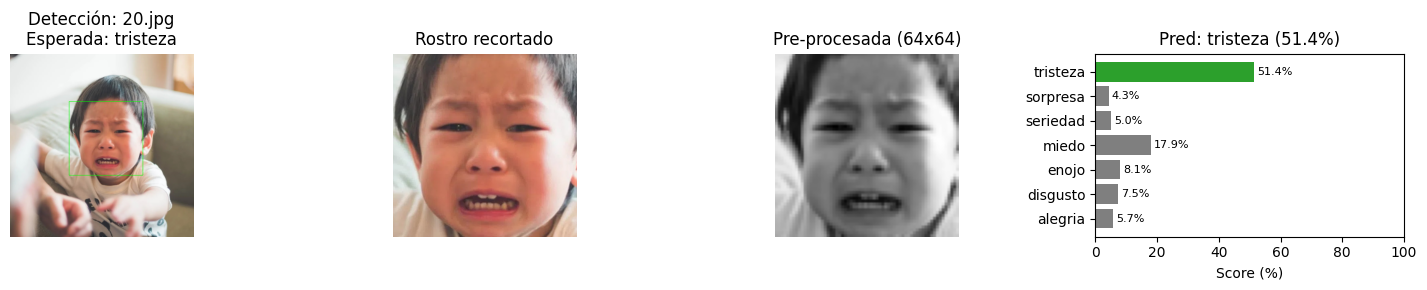

Imagen     | Esperada   | Punto 4 (sin recorte)  | Punto 5 (con recorte) 
------------------------------------------------------------------------
01.jpg     | alegria    | tristeza (92.0%)       | alegria (93.7%)       
02.jpg     | alegria    | tristeza (45.3%)       | enojo (89.8%)         
03.jpg     | sorpresa   | tristeza (45.9%)       | sorpresa (81.5%)      
04.jpg     | tristeza   | tristeza (79.8%)       | disgusto (41.1%)      
05.jpg     | tristeza   | tristeza (97.8%)       | seriedad (32.6%)      
06.jpg     | alegria    | enojo (41.3%)          | miedo (43.0%)         
07.jpg     | enojo      | tristeza (65.7%)       | sorpresa (25.5%)      
08.jpg     | sorpresa   | tristeza (96.7%)       | tristeza (40.6%)      
09.jpg     | enojo      | tristeza (49.5%)       | sorpresa (48.5%)      
10.jpg     | disgusto   | disgusto (53.0%)       | alegria (49.5%)       
11.jpg     | miedo      | tristeza (60.0%)       | seriedad (46.2%)      
12.jpg     | miedo      | tristeza (90.

In [32]:
# Procesamiento de imágenes con el recorte de rostro e inferencia
resultados_p5 = []

for arch in archivos:
    ruta = os.path.join(photos_dir, arch)
    img_box_rgb, face_rgb = detectar_y_recortar_rostro(ruta)

    # Pre-procesamiento del modelo sobre el recorte
    pil_face = Image.fromarray(face_rgb)
    tensor = val_dataset(pil_face).unsqueeze(0).to(device)

    with torch.no_grad():
        salida = model(tensor)
        probs = torch.softmax(salida, dim=1).squeeze(0).cpu().numpy()

    pred_idx = np.argmax(probs)
    pred_clase = nombres_clases[pred_idx]
    conf = probs[pred_idx] * 100.0
    esperada = etiquetas_esperadas.get(arch, 'desconocida')

    img_preproc = tensor.squeeze().cpu().numpy() * desvio + media
    img_preproc = np.clip(img_preproc, 0, 1)

    resultados_p5.append({
        'archivo': arch,
        'img_box_rgb': img_box_rgb,
        'face_rgb': face_rgb,
        'img_preproc': img_preproc,
        'probs': probs,
        'predicha': pred_clase,
        'esperada': esperada,
        'confianza': conf
    })

# Visualización requerida en la consigna
for r in resultados_p5:
    fig, ax = plt.subplots(1, 4, figsize=(15, 3))

    # 1. Imagen original con detección
    ax[0].imshow(r['img_box_rgb'])
    ax[0].set_title(f"Detección: {r['archivo']}\nEsperada: {r['esperada']}")
    ax[0].axis('off')

    # 2. Rostro recortado (1:1)
    ax[1].imshow(r['face_rgb'])
    ax[1].set_title("Rostro recortado")
    ax[1].axis('off')

    # 3. Pre-procesada
    ax[2].imshow(r['img_preproc'], cmap='gray')
    ax[2].set_title("Pre-procesada (64x64)")
    ax[2].axis('off')

    # 4. Scores
    scores = r['probs'] * 100
    y_pos = np.arange(len(nombres_clases))
    colores = ['#2ca02c' if c == r['predicha'] else '#7f7f7f' for c in nombres_clases]
    ax[3].barh(y_pos, scores, color=colores)
    ax[3].set_yticks(y_pos)
    ax[3].set_yticklabels(nombres_clases)
    ax[3].set_xlim(0, 100)
    ax[3].set_xlabel('Score (%)')
    ax[3].set_title(f"Pred: {r['predicha']} ({r['confianza']:.1f}%)")

    for i, v in enumerate(scores):
        ax[3].text(v + 1, i, f"{v:.1f}%", va='center', fontsize=8)

    plt.tight_layout()
    plt.show()

# Comparación rápida entre Punto 4 y Punto 5
print(f"{'Imagen':<10} | {'Esperada':<10} | {'Punto 4 (sin recorte)':<22} | {'Punto 5 (con recorte)':<22}")
print("-" * 72)
for r4, r5 in zip(resultados_p4, resultados_p5):
    res_p4 = f"{r4['predicha']} ({r4['confianza']:.1f}%)"
    res_p5 = f"{r5['predicha']} ({r5['confianza']:.1f}%)"
    print(f"{r4['archivo']:<10} | {r4['esperada']:<10} | {res_p4:<22} | {res_p5:<22}")


### Análisis de errores y conclusiones finales (Punto 5)

#### Análisis de errores
1. **Similitud entre emociones**:
   - **Disgusto y Enojo**: Al igual que se observó en la matriz de confusión del punto 3, varias caras de disgusto (como `10.jpg` o `18.jpg`) se confunden con enojo. Ambas expresiones comparten el ceño fruncido y tensión en la zona de la boca, rasgos que al reducirse a 64x64 en escala de grises resultan difíciles de discriminar.
   - **Seriedad y Tristeza**: En rostros relajados o neutros (`16.jpg`, `17.jpg`, `19.jpg`), una ligera inclinación de las comisuras hacia abajo suele ser interpretada por el modelo como tristeza en lugar de seriedad.
2. **Mezcla de emociones en una misma foto**:
   - En expresiones más complejas (por ejemplo `08.jpg` donde la persona se encoge de hombros con duda, o `13.jpg` donde hay gesto de preocupación y manos en la cabeza), coexisten elementos de sorpresa, miedo y seriedad a la vez. El modelo no predice una única emoción con 100% de certeza, sino que reparte la probabilidad entre dos o tres clases candidatas.
   - En fotos como `11.jpg` y `12.jpg` (ojos muy abiertos con cara de susto), hay una frontera difusa entre sorpresa y miedo, ya que ambas abren los ojos y la boca de forma similar.

#### Comparación con el Punto 4 y conclusiones finales
- **Aislamiento del rostro**: El clasificador de Haar elimina el fondo, ropa y manos, enfocando la convolución únicamente en la zona facial. Esto aumentó notablemente la certeza (score de probabilidad) de la clase ganadora en la mayoría de los casos.
- **Conservación de la relación de aspecto**: Al calcular un cuadrado centrado en el rostro (`side = max(w, h)`) antes de hacer el resize a 64x64, la cara no se deforma al redimensionarse, lo que ayuda a que los filtros convolucionales capturen las proporciones reales de ojos, nariz y boca.
- **Ajuste de parámetros**: Para lograr detectar todos los rostros fue necesario ajustar `scaleFactor`, `minNeighbors` y `minSize` de forma más permisiva, ya que los valores por defecto de Haar suelen fallar en caras inclinadas o con iluminación no uniforme.
- **Conclusión general**: El experimento confirma que para un sistema de reconocimiento de emociones en imágenes reales, una red convolucional requiere indispensablemente una etapa previa de detección y recorte de rostros; clasificar la imagen completa sin recortar introduce demasiado ruido y distorsión geométrica.
